In [27]:
import sys
print(sys.executable)

/Users/akinsholaakinade/Projects/sentinel/.venv/bin/python


In [28]:
from pathlib import Path

import pandas as pd
pd.set_option("display.float_format", "{:,.2f}".format)


RAW_DIR = Path("..") / "data" / "raw"

train = pd.read_csv(RAW_DIR / "fraudTrain.csv", index_col=0)
test = pd.read_csv(RAW_DIR / "fraudTest.csv", index_col=0)
df = pd.concat([train, test], ignore_index=True)

print("train:", train.shape)
print("test: ", test.shape)
print("all:  ", df.shape)

train: (1296675, 22)
test:  (555719, 22)
all:   (1852394, 22)


In [29]:
df.head(2).T

,0,1
trans_date_trans_time,2019-01-01 00:00:18,2019-01-01 00:00:44
cc_num,2703186189652095,630423337322
merchant,"fraud_Rippin, Kub and Mann","fraud_Heller, Gutmann and Zieme"
category,misc_net,grocery_pos
amt,4.97,107.23
first,Jennifer,Stephanie
last,Banks,Gill
gender,F,F
street,561 Perry Cove,43039 Riley Greens Suite 393
city,Moravian Falls,Orient


In [30]:
df.dtypes

trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

In [31]:
df.isna().sum()

trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [32]:
print("duplicate rows:", df.duplicated().sum())
print("duplicate transaction IDs:", df["trans_num"].duplicated().sum())

duplicate rows: 0
duplicate transaction IDs: 0


In [33]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cc_num,"1,852,394.00","417,386,038,393,710,400.00","1,309,115,265,318,735,104.00","60,416,207,185.00","180,042,946,491,150.00","3,521,417,320,836,166.00","4,642,255,475,285,942.00","4,992,346,398,065,154,048.00"
amt,"1,852,394.00",70.06,159.25,1.00,9.64,47.45,83.10,"28,948.90"
zip,"1,852,394.00","48,813.26","26,881.85","1,257.00","26,237.00","48,174.00","72,042.00","99,921.00"
lat,"1,852,394.00",38.54,5.07,20.03,34.67,39.35,41.94,66.69
long,"1,852,394.00",-90.23,13.75,-165.67,-96.80,-87.48,-80.16,-67.95
city_pop,"1,852,394.00","88,643.67","301,487.62",23.00,741.00,"2,443.00","20,328.00","2,906,700.00"
unix_time,"1,852,394.00","1,358,674,218.83","18,195,081.39","1,325,376,018.00","1,343,016,823.75","1,357,089,331.00","1,374,581,485.25","1,388,534,374.00"
merch_lat,"1,852,394.00",38.54,5.11,19.03,34.74,39.37,41.96,67.51
merch_long,"1,852,394.00",-90.23,13.76,-166.67,-96.90,-87.44,-80.25,-66.95
is_fraud,"1,852,394.00",0.01,0.07,0.00,0.00,0.00,0.00,1.00


In [34]:
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

print("first:", df["trans_date_trans_time"].min())
print("last: ", df["trans_date_trans_time"].max())
print("type: ", df["trans_date_trans_time"].dtype)

first: 2019-01-01 00:00:18
last:  2020-12-31 23:59:34
type:  datetime64[us]


In [35]:
counts = df["is_fraud"].value_counts()
rates = df["is_fraud"].value_counts(normalize=True) * 100

print(counts)
print()
print(rates.round(3))

is_fraud
0    1842743
1       9651
Name: count, dtype: int64

is_fraud
0   99.48
1    0.52
Name: proportion, dtype: float64


In [36]:
per_customer = df.groupby("cc_num").size()

print("customers:", per_customer.shape[0])
print()
print(per_customer.describe())

customers: 999

count     999.00
mean    1,854.25
std     1,175.57
min         6.00
25%       740.00
50%     1,471.00
75%     2,917.00
max     4,392.00
dtype: float64


In [37]:
thin = per_customer[per_customer < 100]

print("customers with fewer than 100 transactions:", len(thin))
print()
print(thin.sort_values())

customers with fewer than 100 transactions: 91

cc_num
4295296907373           6
4975457191020           7
501894933032            7
340187018810220         7
4352307151555405069     7
                       ..
3588001568691267       14
3521260686633367       15
501851115094           15
4168696938629925       15
4593569795412          19
Length: 91, dtype: int64


In [38]:
df["thin_history"] = df["cc_num"].isin(thin.index)

summary = df.groupby("thin_history")["is_fraud"].agg(["count", "sum", "mean"])
summary["mean"] = summary["mean"] * 100

print(summary)

                count   sum   mean
thin_history                      
False         1851490  8747   0.47
True              904   904 100.00


In [39]:
by_category = df.groupby("category")["is_fraud"].agg(["count", "sum", "mean"])
by_category["mean"] = by_category["mean"] * 100

print(by_category.sort_values("mean", ascending=False))

                 count   sum  mean
category                          
shopping_net    139322  2219  1.59
misc_net         90654  1182  1.30
grocery_pos     176191  2228  1.26
shopping_pos    166463  1056  0.63
gas_transport   188029   772  0.41
misc_pos        114229   322  0.28
grocery_net      64878   175  0.27
travel           57956   156  0.27
personal_care   130085   290  0.22
entertainment   134118   292  0.22
kids_pets       161727   304  0.19
food_dining     130729   205  0.16
home            175460   265  0.15
health_fitness  122553   185  0.15


In [40]:
print(df.groupby("is_fraud")["amt"].describe().T)

is_fraud            0        1
count    1,842,743.00 9,651.00
mean            67.65   530.66
std            153.55   391.03
min              1.00     1.06
25%              9.61   240.07
50%             47.24   390.00
75%             82.56   902.37
max         28,948.90 1,376.04


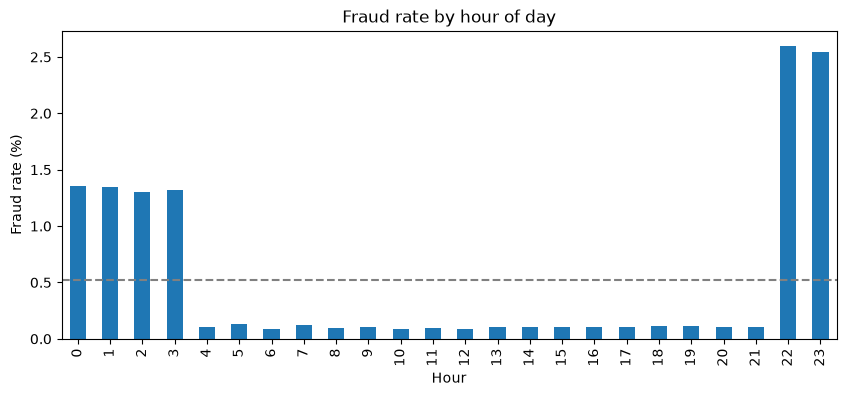

In [41]:
import matplotlib.pyplot as plt

hour = df["trans_date_trans_time"].dt.hour
fraud_rate_by_hour = df.groupby(hour)["is_fraud"].mean() * 100

fraud_rate_by_hour.plot(kind="bar", figsize=(10, 4))
plt.axhline(0.52, linestyle="--", color="gray")
plt.title("Fraud rate by hour of day")
plt.xlabel("Hour")
plt.ylabel("Fraud rate (%)")
plt.show()